# 04 - Low-rank factorization

In [2]:
import sys; sys.path.append("..")
%load_ext autoreload
%autoreload 2

import torch, torch.nn as nn
import pandas as pd
import matplotlib.pyplot as plt
from src.data import get_dataloaders
from src.models import build_model
from src.quant import fold_bn
from src.train import evaluate
from src.metrics import profile_model, save_result
from src.lowrank import get_targets, compute_svds, rank_for_energy, build_lowrank, sweep_lowrank

device = torch.device("cpu")
_, val_loader, test_loader = get_dataloaders("../data", batch_size=128)


def load_folded(name):
    model = build_model(name)
    model.load_state_dict(torch.load(f"../checkpoints/{name}_baseline.pt", map_location="cpu"))
    return fold_bn(model)

layer  0       (64, 27) | rango   27 | k@95% =   10 | pareggio k <   19.0 | conviene
layer  1     (128, 576) | rango  128 | k@95% =   75 | pareggio k <  104.7 | conviene
layer  2    (256, 1152) | rango  256 | k@95% =  176 | pareggio k <  209.5 | conviene
layer  3    (256, 2304) | rango  256 | k@95% =  207 | pareggio k <  230.4 | conviene
layer  4    (512, 2304) | rango  512 | k@95% =  374 | pareggio k <  418.9 | conviene
layer  5    (512, 4608) | rango  512 | k@95% =  427 | pareggio k <  460.8 | conviene
layer  6    (512, 4608) | rango  512 | k@95% =  429 | pareggio k <  460.8 | conviene
layer  7    (512, 4608) | rango  512 | k@95% =  437 | pareggio k <  460.8 | conviene
layer  8   (2048, 2048) | rango 2048 | k@95% = 1218 | pareggio k < 1024.0 | NON conviene
layer  9   (1024, 2048) | rango 1024 | k@95% =  753 | pareggio k <  682.7 | NON conviene


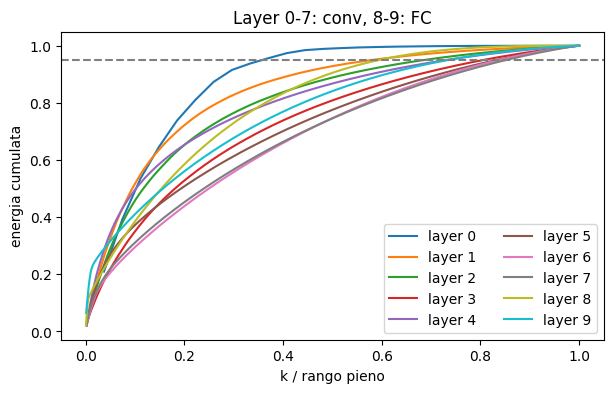

In [3]:
# cerco di capire se conviene fare low-rank approximation dei layer convoluzionali e fully-connected

folded = load_folded("teacher")
svds = compute_svds(folded)

for i, ((U, S, Vh), layer) in enumerate(zip(svds, get_targets(folded))):
    W = layer.weight.data.reshape(layer.weight.shape[0], -1)
    k = rank_for_energy(S, 0.95)
    be = W.shape[0] * W.shape[1] / sum(W.shape)
    print(f"layer {i:2d} {str(tuple(W.shape)):>14} | rango {S.numel():4d} | k@95% = {k:4d} | "
          f"pareggio k < {be:6.1f} | {'conviene' if k < be else 'NON conviene'}")

fig, ax = plt.subplots(figsize=(7, 4))
for i, (U, S, Vh) in enumerate(svds):
    energy = (S ** 2).cumsum(0) / (S ** 2).sum()
    ax.plot((torch.arange(1, len(S) + 1) / len(S)).numpy(), energy.numpy(), label=f"layer {i}")
ax.axhline(0.95, color="gray", linestyle="--")
ax.set_xlabel("k / rango pieno"); ax.set_ylabel("energia cumulata")
ax.set_title("Layer 0-7: conv, 8-9: FC"); ax.legend(ncol=2); plt.show()

In [4]:
#test di correttezza: lowrank mantenendo tutti i valori singolari deve dare lo stesso risultato del folded
lr_full, _ = build_lowrank(folded, svds, tau=1.0, skip_first=0, force=True)
x, _ = next(iter(val_loader))
with torch.no_grad():
    print("max |diff|:", (folded(x) - lr_full(x)).abs().max().item())   # atteso: errore numerico (~1e-4 o meno)

c:\Users\Pietr\Desktop\Model-Compression\.venv\lib\site-packages\torch\utils\data\dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


max |diff|: 6.29425048828125e-05


Ricerca a griglia 

In [5]:
TAUS = [1.0, 0.99, 0.97, 0.95, 0.9, 0.8]
SKIP_FIRST = 2

lowrank = {}
for name in ["teacher", "student"]:
    folded = load_folded(name)
    base_acc, rows, svds = sweep_lowrank(folded, val_loader, device, TAUS, SKIP_FIRST)
    lowrank[name] = (folded, svds, base_acc, pd.DataFrame(rows))
    print(f"\n{name}")
    display(lowrank[name][3])

tau 1.00 | val 89.84 (Δ -0.00) | 15,525,258 params | 215.7M MACs | 0 layer fattorizzati
tau 0.99 | val 89.84 (Δ -0.00) | 15,525,258 params | 215.7M MACs | 0 layer fattorizzati
tau 0.97 | val 89.72 (Δ -0.12) | 15,439,626 params | 212.8M MACs | 5 layer fattorizzati
tau 0.95 | val 89.62 (Δ -0.22) | 14,834,058 params | 199.5M MACs | 6 layer fattorizzati
tau 0.90 | val 89.26 (Δ -0.58) | 13,349,770 params | 172.7M MACs | 8 layer fattorizzati
tau 0.80 | val 88.52 (Δ -1.32) | 9,926,538 params | 132.8M MACs | 8 layer fattorizzati

teacher


,tau,val_acc,drop,params,macs,n_factorized
0,1.00,0.8984,0.00,15525258,215689216,0
1,0.99,0.8984,0.00,15525258,215689216,0
2,0.97,0.8972,0.12,15439626,212826112,5
3,0.95,0.8962,0.22,14834058,199493632,6
4,0.90,0.8926,0.58,13349770,172703744,8
5,0.80,0.8852,1.32,9926538,132766720,8


c:\Users\Pietr\Desktop\Model-Compression\.venv\lib\site-packages\torch\utils\data\dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


tau 1.00 | val 74.92 (Δ -0.00) | 110,021 params | 1.6M MACs | 0 layer fattorizzati
tau 0.99 | val 74.92 (Δ -0.00) | 110,021 params | 1.6M MACs | 0 layer fattorizzati
tau 0.97 | val 75.02 (Δ +0.10) | 109,720 params | 1.6M MACs | 1 layer fattorizzati
tau 0.95 | val 67.66 (Δ -7.26) | 104,080 params | 1.5M MACs | 7 layer fattorizzati
tau 0.90 | val 51.86 (Δ -23.06) | 84,989 params | 1.4M MACs | 8 layer fattorizzati
tau 0.80 | val 29.02 (Δ -45.90) | 60,220 params | 1.1M MACs | 8 layer fattorizzati

student


,tau,val_acc,drop,params,macs,n_factorized
0,1.00,0.7492,0.00,110021,1625629,0
1,0.99,0.7492,0.00,110021,1625629,0
2,0.97,0.7502,-0.10,109720,1620813,1
3,0.95,0.6766,7.26,104080,1549494,7
4,0.90,0.5186,23.06,84989,1367113,8
5,0.80,0.2902,45.90,60220,1117194,8


Mantenimento della miglior config

In [6]:
MAX_DROP = 3.0   # punti persi sulla val

for name, (folded, svds, base_acc, df) in lowrank.items():
    ok = df[df["drop"] <= MAX_DROP]
    best = ok.sort_values(["params", "drop"]).iloc[0]
    lr_model, info = build_lowrank(folded, svds, best["tau"], SKIP_FIRST)

    _, test_acc = evaluate(lr_model, test_loader, device)
    prof = profile_model(lr_model, dtype="fp32")
    save_result(f"{name}_lowrank", val_acc=best["val_acc"], test_acc=test_acc,
                tau=best["tau"], skip_first=SKIP_FIRST, **prof)
    print(f"{name}: tau {best['tau']} | {best['n_factorized']:.0f} layer fattorizzati | test {test_acc * 100:.2f} | "
          f"{prof['params']:,} params | {prof['macs'] / 1e6:.1f}M MACs | {prof['latency_ms_median']:.2f} ms")

c:\Users\Pietr\Desktop\Model-Compression\.venv\lib\site-packages\torch\utils\data\dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


teacher: tau 0.8 | 8 layer fattorizzati | test 87.83 | 9,926,538 params | 132.8M MACs | 11.41 ms
student: tau 0.97 | 1 layer fattorizzati | test 75.58 | 109,720 params | 1.6M MACs | 0.55 ms
